# BT4012 Fraud Analytics Group 14: Model comparison and misclassification analysis

Compares **RGCN-MLP** (`model.ipynb`) with **XGBoost** (`model_classical.ipynb`) at a review budget of the top 5% of
companies per test year (2019-2022), and looks at the frauds both miss. Reads saved predictions only (no retraining,
nothing saved).

Terms: **repeat candidate** = fraud last year; **first-time candidate** = no fraud last year. **History rule** = rank
last year's frauds first, then by model score (`model_score + fraud_last_year`), applied the same way to every model.
**First-time full budget** = the whole 5% budget given to first-time candidates only.

## Libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score

## Configuration

In [2]:
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = ROOT / "results"
EDGE_PATH = PROCESSED_DIR / "graph" / "company_edges.parquet"

KEYS = ["nodeID", "Year"]
TEST_YEARS = [2019, 2020, 2021, 2022]
BUDGET = 0.05                                    # review budget: top 5% of companies per test year
BUDGETS = [0.02, 0.05, 0.10]                     # budgets for the business-integration table
FIRST_TIME_SHARES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
N_BOOT, SEED = 2000, 0

MODELS = {"XGBoost": "xgb", "MLP": "mlp", "RGCN": "rgcn", "RGCN-MLP": "ens"}
COLORS = {"RGCN-MLP": "#1baf7a", "XGBoost": "#eb6834", "MLP": "#2a78d6", "RGCN": "#7a5af5",
          "History rule only": "#52514e", "Perfect ranking": "#b8b7b1"}
GROUPS = ["missed by both", "caught by at least one", "first-time non-fraud"]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1",
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
                     "legend.frameon": False, "font.size": 9.5})

## Helpers

In [3]:
def n_slots(n, share=BUDGET):
    return int(np.ceil(round(share * n, 9)))     # round() avoids float error, e.g. 0.05 * 0.9 = 0.045000000000000005


def top_k(scores, k):
    # True for the k highest scores; ties go to the earlier row (rows are sorted by Year, nodeID)
    mask = np.zeros(len(scores), dtype=bool)
    mask[np.argsort(-np.asarray(scores, dtype=float), kind="stable")[:k]] = True
    return mask


def flag_top(col, rows=None, share=BUDGET):
    # flag the top 5% of each year's companies by `col`, choosing only among `rows` (default: everyone)
    rows = pd.Series(True, index=wide.index) if rows is None else rows
    flags = pd.Series(False, index=wide.index)
    for year in TEST_YEARS:
        in_year = wide["Year"] == year
        idx = wide.index[in_year & rows]
        flags[idx] = top_k(wide.loc[idx, col].to_numpy(), n_slots(in_year.sum(), share))
    return flags


def caught_by_year(col):
    return wide.loc[flag_top(col), ["Year", "Label"]].groupby("Year")["Label"].sum()


def caught_at_budget(score_col, budget, first_time_share):
    # two queues: repeat candidates get (1 - first_time_share) of the budget, first-time candidates the rest;
    # unused repeat slots roll over to the first-time queue
    out = dict.fromkeys(["repeat reviews", "repeat caught", "first-time reviews", "first-time caught"], 0)
    for _, g in wide.groupby("Year"):
        repeat = g["fraud_last_year"].to_numpy() == 1
        slots = n_slots(len(g), budget)
        repeat_slots = min(n_slots(len(g), budget * (1 - first_time_share)), repeat.sum())
        for name, rows, k in [("repeat", repeat, repeat_slots), ("first-time", ~repeat, slots - repeat_slots)]:
            out[f"{name} reviews"] += k
            out[f"{name} caught"] += int(g["Label"].to_numpy()[rows][top_k(g[score_col].to_numpy()[rows], k)].sum())
    out["total caught"] = out["repeat caught"] + out["first-time caught"]
    return out


METRICS = {"caught": lambda y, s, k: y[top_k(s, k)].sum(),
           "PR-AUC": lambda y, s, k: average_precision_score(y, s),
           "ROC-AUC": lambda y, s, k: roc_auc_score(y, s)}


def paired_bootstrap(col_a, col_b, rows, metrics):
    # resample companies within each year (same rows for both models), keep each year's 5% slot count;
    # difference = A - B, summed over years for "caught", averaged over years for the AUCs
    data = [(wide.loc[(wide["Year"] == y) & rows, ["Label", col_a, col_b]].to_numpy(), n_slots((wide["Year"] == y).sum()))
            for y in TEST_YEARS]

    def difference(metric, samples):
        diffs = [METRICS[metric](d[i, 0], d[i, 1], k) - METRICS[metric](d[i, 0], d[i, 2], k) for (d, k), i in zip(data, samples)]
        return np.sum(diffs) if metric == "caught" else np.mean(diffs)

    rows_out = []
    for metric in metrics:
        rng = np.random.default_rng(SEED)        # same resamples for every metric
        boot = np.array([difference(metric, [np.sort(rng.integers(0, len(d), len(d))) for d, _ in data]) for _ in range(N_BOOT)])
        rows_out.append({"metric": metric, "difference": difference(metric, [np.arange(len(d)) for d, _ in data]),
                         "95% low": np.percentile(boot, 2.5), "95% high": np.percentile(boot, 97.5),
                         "A better %": 100 * (boot > 0).mean(), "tie %": 100 * (boot == 0).mean(), "B better %": 100 * (boot < 0).mean()})
    return pd.DataFrame(rows_out).set_index("metric")

## Loading predictions
`classical_predictions.csv` scores every split's rows, so a test-year row appears once per split that contains it; the
first copy comes from the split where that year is the test year (out-of-sample). The assert checks that these rows
reproduce the AUCs in `classical_results.csv`.

In [4]:
labels = pd.read_csv(DATA_DIR / "splits" / "temporal_splits.csv")[KEYS + ["Label"]].drop_duplicates(KEYS)
labels = labels.merge(labels.assign(Year=labels["Year"] + 1).rename(columns={"Label": "fraud_last_year"}), on=KEYS, how="left")
labels["fraud_last_year"] = labels["fraud_last_year"].fillna(0).astype(int)
LAST_LABEL_YEAR = labels["Year"].max()

rgcn = pd.read_csv(RESULTS_DIR / "rgcn_predictions.csv")
wide = rgcn.query("model == 'ens'")[KEYS + ["Label"]]
for m in ["ens", "mlp", "rgcn"]:
    wide = wide.merge(rgcn.query("model == @m")[KEYS + ["model_score"]].rename(columns={"model_score": m}), on=KEYS)

classical = pd.read_csv(RESULTS_DIR / "classical_predictions.csv")
classical = classical[classical["Year"].isin(TEST_YEARS)].drop_duplicates(KEYS + ["model"], keep="first")
reported = pd.read_csv(RESULTS_DIR / "classical_results.csv").drop_duplicates(["model", "test_year"]).set_index(["model", "test_year"])["test_auc"]
for (m, year), r in classical[classical["model"].isin(["xgb", "xgb_tuned"])].groupby(["model", "Year"]):
    assert abs(roc_auc_score(r["Label"], r["score"]) - reported[(m, year)]) < 1e-6, f"{m} {year}: AUC differs from classical_results.csv"
for m in ["xgb", "xgb_tuned"]:
    wide = wide.merge(classical.loc[classical["model"] == m, KEYS + ["score"]].rename(columns={"score": m}), on=KEYS)

wide = wide.merge(labels[KEYS + ["fraud_last_year"]], on=KEYS, how="left").sort_values(KEYS).reset_index(drop=True)
for m in ["ens", "mlp", "rgcn", "xgb", "xgb_tuned"]:
    wide[f"{m}_hist"] = wide[m] + wide["fraud_last_year"]          # history rule: last year's frauds first

REPEAT, FIRST, FRAUD = wide["fraud_last_year"] == 1, wide["fraud_last_year"] == 0, wide["Label"] == 1
print(f"{len(wide):,} test company-years, {FRAUD.sum()} frauds ({(FRAUD & FIRST).sum()} first-time, {(FRAUD & REPEAT).sum()} repeat)")

17,985 test company-years, 727 frauds (204 first-time, 523 repeat)


## 1. Headline: frauds caught at 5%
"History rule only" ranks last year's frauds first and everyone else at random (mean of 100 seeds). xgb_tuned is
shown for reference only: it was tuned on 2021, which is also a test year.

In [5]:
headline = pd.DataFrame({"RGCN-MLP": caught_by_year("ens_hist"),
                         "XGBoost (score alone)": caught_by_year("xgb"),
                         "XGBoost + history rule": caught_by_year("xgb_hist"),
                         "xgb_tuned + history rule (reference)": caught_by_year("xgb_tuned_hist")}).T
random_runs = []
for seed in range(100):
    wide["random_hist"] = np.random.default_rng(seed).random(len(wide)) + wide["fraud_last_year"]
    random_runs.append(caught_by_year("random_hist"))
headline.loc["History rule only"] = pd.DataFrame(random_runs).mean()
headline.loc["Perfect ranking"] = [min(wide.loc[wide["Year"] == y, "Label"].sum(), n_slots((wide["Year"] == y).sum())) for y in TEST_YEARS]
headline["Total"] = headline.sum(axis=1)
headline.round(1)

Year,2019,2020,2021,2022,Total
RGCN-MLP,144.0,131.0,137.0,101.0,513.0
XGBoost (score alone),80.0,87.0,70.0,60.0,297.0
XGBoost + history rule,142.0,131.0,137.0,100.0,510.0
xgb_tuned + history rule (reference),142.0,131.0,137.0,99.0,509.0
History rule only,136.3,131.0,136.4,98.4,502.1
Perfect ranking,191.0,207.0,183.0,123.0,704.0


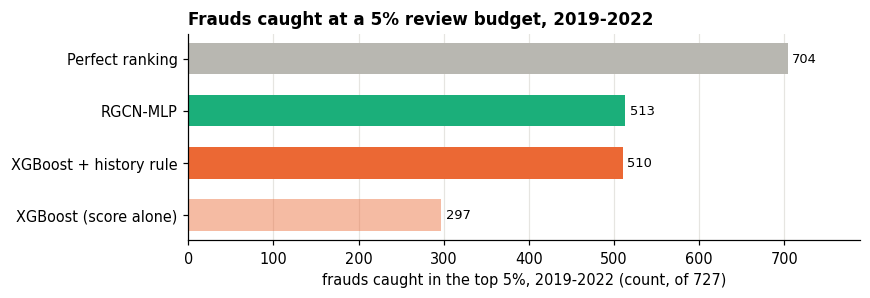

In [6]:
CHART = {"Perfect ranking": COLORS["Perfect ranking"], "RGCN-MLP": COLORS["RGCN-MLP"],
         "XGBoost + history rule": COLORS["XGBoost"], "XGBoost (score alone)": COLORS["XGBoost"]}
totals = headline.loc[list(CHART), "Total"][::-1]          # Perfect ranking at the top
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(totals.index, totals, color=[CHART[n] for n in totals.index], height=0.6)
bars[0].set_alpha(0.45)                                     # XGBoost (score alone): same model, no history rule
ax.bar_label(bars, labels=[f"{v:.0f}" for v in totals], padding=3, fontsize=8.5)
ax.set(xlabel=f"frauds caught in the top 5%, 2019-2022 (count, of {FRAUD.sum()})", xlim=(0, totals.max() * 1.12),
       title="Frauds caught at a 5% review budget, 2019-2022")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**Is the RGCN-MLP lead real?** Paired bootstrap of frauds caught (A = RGCN-MLP, B = XGBoost, both under the history
rule), and how much of the budget the history rule fills before any model score is used.

In [7]:
display(paired_bootstrap("ens_hist", "xgb_hist", pd.Series(True, index=wide.index), ["caught"]).round(2))

budget = pd.DataFrame({"slots (5%)": [n_slots((wide["Year"] == y).sum()) for y in TEST_YEARS],
                       "repeat candidates": REPEAT.groupby(wide["Year"]).sum().to_numpy()}, index=TEST_YEARS)
budget["left for first-time"] = (budget["slots (5%)"] - budget["repeat candidates"]).clip(lower=0)
budget.loc["Total"] = budget.sum()
filled = budget.loc["Total", "slots (5%)"] - budget.loc["Total", "left for first-time"]
print(f"{filled} of {budget.loc['Total', 'slots (5%)']} slots ({filled / budget.loc['Total', 'slots (5%)']:.0%}) go to last year's frauds")
budget

,difference,95% low,95% high,A better %,tie %,B better %
metric,,,,,,
caught,3.0,-7.0,13.0,68.65,6.7,24.65


775 of 901 slots (86%) go to last year's frauds


,slots (5%),repeat candidates,left for first-time
2019,191,221,0
2020,214,210,4
2021,239,201,38
2022,257,173,84
Total,901,805,126


## 2. First-time vs repeat frauds
Under the history rule, who fills the 5% budget? Then the **first-time full budget**: each model's ranking of
first-time candidates on its own (out of 204 first-time frauds; AUCs averaged over the four years).

In [8]:
FLAGS = {name: flag_top(f"{m}_hist") for name, m in MODELS.items()}
display(pd.DataFrame({name: {"repeat flagged": (FLAGS[name] & REPEAT).sum(), "repeat frauds caught": (FLAGS[name] & REPEAT & FRAUD).sum(),
                             "first-time flagged": (FLAGS[name] & FIRST).sum(), "first-time frauds caught": (FLAGS[name] & FIRST & FRAUD).sum()}
                      for name in ["RGCN-MLP", "XGBoost"]}).T)

FT_FLAGS = {name: flag_top(m, rows=FIRST) for name, m in MODELS.items()}
rows = []
for name, m in MODELS.items():
    for year in TEST_YEARS:
        sub = wide[(wide["Year"] == year) & FIRST]
        rows.append({"model": name, "Year": year, "caught": (FT_FLAGS[name] & FRAUD & (wide["Year"] == year)).sum(),
                     "PR-AUC": average_precision_score(sub["Label"], sub[m]), "ROC-AUC": roc_auc_score(sub["Label"], sub[m])})
first_time = pd.DataFrame(rows).pivot(index="model", columns="Year").reindex(list(MODELS))
first_time[("caught", "Total")] = first_time["caught"].sum(axis=1)
first_time[("PR-AUC", "Mean")] = first_time["PR-AUC"].mean(axis=1)
first_time[("ROC-AUC", "Mean")] = first_time["ROC-AUC"].mean(axis=1)
first_time = first_time.sort_index(axis=1, level=0, sort_remaining=False)
first_time.round(3)

,repeat flagged,repeat frauds caught,first-time flagged,first-time frauds caught
RGCN-MLP,775,509,126,4
XGBoost,775,507,126,3


PR-AUC                             ROC-AUC                       \
Year       2019   2020   2021   2022   Mean    2019   2020   2021   2022   
model                                                                      
XGBoost   0.043  0.060  0.024  0.023  0.037   0.751  0.708  0.687  0.824   
MLP       0.045  0.061  0.027  0.032  0.041   0.770  0.737  0.702  0.861   
RGCN      0.048  0.060  0.021  0.038  0.042   0.763  0.733  0.685  0.861   
RGCN-MLP  0.047  0.061  0.023  0.036  0.042   0.771  0.739  0.702  0.863   

                caught                       
Year       Mean   2019 2020 2021 2022 Total  
model                                        
XGBoost   0.742     12   18    8    7    45  
MLP       0.767     11   17    8    9    45  
RGCN      0.760     10   16    6   11    43  
RGCN-MLP  0.769     11   16    7   11    45

In [9]:
# A = RGCN-MLP, B = XGBoost, first-time candidates only
paired_bootstrap("ens", "xgb", FIRST, ["caught", "PR-AUC", "ROC-AUC"]).round(3)

,difference,95% low,95% high,A better %,tie %,B better %
metric,,,,,,
caught,0.000,-14.000,12.00,44.2,5.0,50.8
PR-AUC,0.004,-0.008,0.02,78.2,0.0,21.8
ROC-AUC,0.026,-0.006,0.06,94.9,0.0,5.1


**Do the models catch the same first-time frauds?** And the repeat frauds of 2019, the only year with more repeat
candidates (221) than slots (191).

In [10]:
a, b = FT_FLAGS["RGCN-MLP"], FT_FLAGS["XGBoost"]
overlap = pd.Series(np.select([a & b, a & ~b, ~a & b], ["both", "only RGCN-MLP", "only XGBoost"], "neither"), index=wide.index)
display(pd.crosstab(wide.loc[FIRST & FRAUD, "Year"], overlap[FIRST & FRAUD], margins=True, margins_name="Total"))

r19 = (wide["Year"] == 2019) & REPEAT & FRAUD
a19, b19 = FLAGS["RGCN-MLP"][r19], FLAGS["XGBoost"][r19]
print(f"2019 repeat frauds ({r19.sum()}): both {(a19 & b19).sum()}, only RGCN-MLP {(a19 & ~b19).sum()}, "
      f"only XGBoost {(~a19 & b19).sum()}, neither {(~a19 & ~b19).sum()}")

col_0,both,neither,only RGCN-MLP,only XGBoost,Total
Year,,,,,
2019,4,37,7,8,56
2020,11,53,5,7,76
2021,3,35,4,5,47
2022,5,12,6,2,25
Total,23,137,22,22,204


2019 repeat frauds (158): both 131, only RGCN-MLP 13, only XGBoost 11, neither 3


## 3. What the missed first-time frauds look like
Groups: first-time frauds **missed by both** models (first-time full budget), **caught by at least one**, and
**first-time non-frauds** for reference. Medians for numbers, % of companies for yes/no features. Revenue growth is
against the company's previous-year revenue; impairments use absolute values because CSMAR switched their sign in 2019;
auditor switch comes from the Audit edges.

In [11]:
wide["group"] = np.select([FIRST & FRAUD & ~(a | b), FIRST & FRAUD & (a | b), FIRST & ~FRAUD], GROUPS, "repeat candidate")

FIN = {"A001000000": "assets", "A002000000": "liabilities", "B002000000": "net_profit", "B001100000": "revenue",
       "A001111000": "receivables", "B001212000": "asset_impairment", "B001307000": "credit_impairment"}
fin = pd.read_parquet(PROCESSED_DIR / "tabular_clean", columns=KEYS + list(FIN)).rename(columns=FIN).astype({"Year": int})
assets = fin["assets"].where(fin["assets"] > 0)
fin = fin.assign(size=np.log(assets), leverage=fin["liabilities"] / assets, roa=fin["net_profit"] / assets,
                 loss=(fin["net_profit"] < 0).astype(float).where(fin["net_profit"].notna()),
                 receivables_to_assets=fin["receivables"] / assets,
                 impairment=(fin["asset_impairment"].abs().fillna(0) + fin["credit_impairment"].abs().fillna(0)) / assets)
fin = fin.merge(fin[KEYS + ["revenue"]].assign(Year=fin["Year"] + 1).rename(columns={"revenue": "revenue_prev"}), on=KEYS, how="left")
fin["revenue_growth"] = fin["revenue"] / fin["revenue_prev"].where(fin["revenue_prev"] > 0) - 1

audit = []
for year in range(labels["Year"].min(), LAST_LABEL_YEAR + 1):
    e = pd.read_csv(DATA_DIR / str(year) / f"edges{year}.csv", header=None, names=["a", "b", "relation"]).query("relation == 'Audit'")
    company_first = e["a"].str.startswith("L")
    audit.append(pd.DataFrame({"nodeID": e["a"].where(company_first, e["b"]), "auditor": e["b"].where(company_first, e["a"]), "Year": year}))
audit = pd.concat(audit).drop_duplicates(KEYS)
fin = fin.merge(audit, on=KEYS, how="left").merge(audit.assign(Year=audit["Year"] + 1).rename(columns={"auditor": "auditor_prev"}), on=KEYS, how="left")
fin["auditor_switch"] = (fin["auditor"] != fin["auditor_prev"]).astype(float).where(fin["auditor"].notna() & fin["auditor_prev"].notna())

text = pd.read_parquet(PROCESSED_DIR / "text_features.parquet", columns=KEYS + ["has_text", "is_truncated"])
industry_cols = [c for c in pq.ParquetDataset(str(PROCESSED_DIR / "tabular_features")).schema.names if c.startswith("industry_")]
industry = pd.read_parquet(PROCESSED_DIR / "tabular_features", columns=KEYS + industry_cols).astype({"Year": int})
onehot = industry[industry_cols].to_numpy()
industry["industry"] = np.where(onehot.any(axis=1), np.array([c.removeprefix("industry_") for c in industry_cols])[onehot.argmax(axis=1)], "none")

profile = (wide.loc[wide["group"].isin(GROUPS), KEYS + ["group"]].merge(fin, on=KEYS, how="left")
           .merge(text, on=KEYS, how="left").merge(industry[KEYS + ["industry"]], on=KEYS, how="left"))
MEDIANS = {"size": "Size: log total assets", "leverage": "Leverage", "roa": "ROA", "revenue_growth": "Revenue growth",
           "receivables_to_assets": "Receivables / assets", "impairment": "Impairment / assets"}
SHARES = {"loss": "Loss-making (%)", "auditor_switch": "Auditor switch (%)", "has_text": "Has text (%)", "is_truncated": "Truncated text (%)"}
by_group = profile.groupby("group")
feature_profile = pd.concat([by_group[list(MEDIANS)].median().rename(columns=MEDIANS),
                             100 * by_group[list(SHARES)].mean().rename(columns=SHARES)], axis=1).T[GROUPS]
feature_profile.loc["companies"] = by_group.size()[GROUPS]
display(feature_profile.round(3))
pd.Series({g: ", ".join(f"{k} ({v:.0%})" for k, v in profile.loc[profile["group"] == g, "industry"].value_counts(normalize=True).head(3).items())
           for g in GROUPS}, name="3 most common industries").to_frame()

group,missed by both,caught by at least one,first-time non-fraud
Size: log total assets,21.646,21.847,22.067
Leverage,0.405,0.619,0.405
ROA,0.022,-0.095,0.039
Revenue growth,0.039,-0.115,0.086
Receivables / assets,0.120,0.146,0.102
Impairment / assets,0.009,0.045,0.006
Loss-making (%),18.978,74.627,14.444
Auditor switch (%),18.333,25.758,10.875
Has text (%),98.540,100.000,97.985
Truncated text (%),10.219,10.448,15.316


,3 most common industries
missed by both,"C39 (12%), I65 (9%), C26 (7%)"
caught by at least one,"I65 (12%), E48 (7%), R86 (6%)"
first-time non-fraud,"C39 (11%), C35 (7%), C26 (7%)"


**What happened the following year?** A look-back description, not a predictor: do missed frauds "unwind"? Scored
years 2019-2021 (no 2023 data for 2022). Large impairment = top 10% of that year's first-time non-frauds; profit drop =
change in ROA in their bottom 10%.

In [12]:
nxt = fin[KEYS + ["roa", "impairment", "loss", "auditor"]].assign(Year=fin["Year"] - 1).add_suffix("_next").rename(columns={"nodeID_next": "nodeID", "Year_next": "Year"})
fp = profile[profile["Year"] < LAST_LABEL_YEAR].merge(nxt, on=KEYS, how="left")
fp["roa_change"] = fp["roa_next"] - fp["roa"]
reference = fp[fp["group"] == "first-time non-fraud"].groupby("Year")
fp["impairment_cut"] = fp["Year"].map(reference["impairment_next"].quantile(0.9))
fp["roa_change_cut"] = fp["Year"].map(reference["roa_change"].quantile(0.1))

FOOTPRINTS = {"loss in the scored year": (fp["loss"].notna(), fp["loss"] == 1),
              "loss next year": (fp["loss_next"].notna(), fp["loss_next"] == 1),
              "large impairment next year": (fp["impairment_next"].notna(), fp["impairment_next"] >= fp["impairment_cut"]),
              "profit drop next year": (fp["roa_change"].notna(), fp["roa_change"] <= fp["roa_change_cut"]),
              "auditor switch next year": (fp["auditor"].notna() & fp["auditor_next"].notna(), fp["auditor_next"] != fp["auditor"])}
footprint = pd.DataFrame({name: {g: f"{100 * (hit & defined & (fp['group'] == g)).sum() / (defined & (fp['group'] == g)).sum():.0f}% "
                                    f"({(hit & defined & (fp['group'] == g)).sum()}/{(defined & (fp['group'] == g)).sum()})" for g in GROUPS}
                          for name, (defined, hit) in FOOTPRINTS.items()}).T
footprint

,missed by both,caught by at least one,first-time non-fraud
loss in the scored year,18% (22/125),70% (38/54),13% (1520/12042)
loss next year,32% (39/123),79% (42/53),17% (1992/11973)
large impairment next year,21% (26/123),57% (30/53),10% (1198/11973)
profit drop next year,17% (21/123),40% (21/53),10% (1198/11973)
auditor switch next year,16% (20/122),26% (14/53),9% (1038/11911)


**How close were the misses?** Percentile of each missed-by-both fraud's score among the same year's first-time
non-frauds (100 = above all of them; the first-time full budget reaches about the top 5-6%). Then the cost of a miss
under the history rule: a fraud that continues becomes a repeat candidate next year; a one-year fraud never does.

In [13]:
rows = []
for name in ["RGCN-MLP", "XGBoost"]:
    m = MODELS[name]
    pct = np.concatenate([100 * np.searchsorted(np.sort(wide.loc[(wide["Year"] == y) & FIRST & ~FRAUD, m]),
                                                wide.loc[(wide["Year"] == y) & (wide["group"] == "missed by both"), m], side="right")
                          / ((wide["Year"] == y) & FIRST & ~FRAUD).sum() for y in TEST_YEARS])
    rows.append({"model": name, "median percentile": np.median(pct), "% above 90th": 100 * (pct > 90).mean(), "% below 50th": 100 * (pct < 50).mean()})
display(pd.DataFrame(rows).set_index("model").round(1))

fraud_years = set(map(tuple, labels.loc[labels["Label"] == 1, KEYS].to_numpy()))
run_length = [next(k for k in range(10) if (n, y + k) not in fraud_years) for n, y in wide[KEYS].to_numpy()]
wide["episode_years"] = np.where(FRAUD, run_length, 0)
outcome = pd.Series(np.select([FRAUD & (wide["Year"] + wide["episode_years"] - 1 >= LAST_LABEL_YEAR), wide["episode_years"] == 1],
                              ["unknown (reaches 2022)", "one-year fraud: never a repeat candidate"], "continues: repeat candidate next year"), index=wide.index)
pd.concat({name: pd.crosstab(wide.loc[FIRST & FRAUD & ~FLAGS[name], "Year"], outcome[FIRST & FRAUD & ~FLAGS[name]], margins=True, margins_name="Total")
           for name in ["RGCN-MLP", "XGBoost"]}, names=["model"])

,median percentile,% above 90th,% below 50th
model,,,
RGCN-MLP,70.2,18.2,24.1
XGBoost,67.9,14.6,27.0


col_0           continues: repeat candidate next year  \
model    Year                                           
RGCN-MLP 2019                                      24   
         2020                                      27   
         2021                                       0   
         2022                                       0   
         Total                                     51   
XGBoost  2019                                      24   
         2020                                      27   
         2021                                       0   
         2022                                       0   
         Total                                     51   

col_0           one-year fraud: never a repeat candidate  \
model    Year                                              
RGCN-MLP 2019                                         23   
         2020                                         23   
         2021                                         20   
         2022                                          0   
         Total                                        66   
XGBoost  2019                                         23   
         2020                                         23   
         2021                                         21   
         2022                                          0   
         Total                                        67   

col_0           unknown (reaches 2022)  Total  
model    Year                                  
RGCN-MLP 2019                        9     56  
         2020                       26     76  
         2021                       26     46  
         2022                       22     22  
         Total                      83    200  
XGBoost  2019                        9     56  
         2020                       26     76  
         2021                       25     46  
         2022                       23     23  
         Total                      83    201

## 4. Why the graph did not help
MLP (no graph) vs RGCN vs RGCN-MLP, with XGBoost for reference. This table is Exhibit 2. RGCN-MLP ranks last year's
frauds with a separate continuation model (`model_score`), which only matters for the 2019 repeat queue: 513 frauds
caught with `model_score` vs 511 with `network_score`.

In [14]:
exhibit2 = pd.DataFrame({"caught at 5% (of 727)": {name: FLAGS[name][FRAUD].sum() for name in MODELS},
                         "first-time caught, full budget (of 204)": first_time[("caught", "Total")],
                         "first-time PR-AUC": first_time[("PR-AUC", "Mean")],
                         "first-time ROC-AUC": first_time[("ROC-AUC", "Mean")]})
display(exhibit2.round(3))
# A = RGCN, B = MLP, first-time candidates only
paired_bootstrap("rgcn", "mlp", FIRST, ["caught", "PR-AUC", "ROC-AUC"]).round(3)

,caught at 5% (of 727),"first-time caught, full budget (of 204)",first-time PR-AUC,first-time ROC-AUC
XGBoost,510,45,0.037,0.742
MLP,510,45,0.041,0.767
RGCN,516,43,0.042,0.760
RGCN-MLP,513,45,0.042,0.769


,difference,95% low,95% high,A better %,tie %,B better %
metric,,,,,,
caught,-2.000,-12.000,8.000,30.50,8.0,61.50
PR-AUC,0.001,-0.008,0.009,54.15,0.0,45.85
ROC-AUC,-0.007,-0.021,0.008,17.15,0.0,82.85


**Do the graph links carry a fraud signal?** For first-time candidates in the training years 2015-2018: each
relation's share of edges, the % of companies with at least one such neighbour, and the lift = fraud rate of companies
with a neighbour that was a fraud last year ÷ fraud rate of those without one.

In [15]:
edges = pd.read_parquet(EDGE_PATH, filters=[("Year", "in", [2015, 2016, 2017, 2018])])
edges = edges.merge(labels.rename(columns={"nodeID": "target_id", "fraud_last_year": "neighbour_fraud_last_year"})[["target_id", "Year", "neighbour_fraud_last_year"]],
                    on=["target_id", "Year"], how="left")
candidates = labels[labels["Year"].between(2015, 2018) & (labels["fraud_last_year"] == 0)]

rows = []
for relation, e in list(edges.groupby("relation")) + [("any relation", edges)]:
    has_neighbour = candidates.set_index(KEYS).index.isin(e.set_index(["source_id", "Year"]).index)
    fraud_neighbour = candidates.set_index(KEYS).index.isin(e[e["neighbour_fraud_last_year"] == 1].set_index(["source_id", "Year"]).index)
    rate_with, rate_without = candidates["Label"][fraud_neighbour].mean(), candidates["Label"][~fraud_neighbour].mean()
    rows.append({"relation": relation, "edge share %": 100 * len(e) / len(edges), "coverage %": 100 * has_neighbour.mean(),
                 "with a fraud neighbour %": 100 * fraud_neighbour.mean(), "lift": rate_with / rate_without})
del edges
pd.DataFrame(rows).set_index("relation").sort_values("edge share %", ascending=False).round(2)

,edge share %,coverage %,with a fraud neighbour %,lift
relation,,,,
any relation,100.00,100.00,97.93,1.25
shared_auditor,49.84,99.69,91.01,1.66
shared_unlisted_investment,30.92,77.23,42.64,0.82
shared_related_individual,11.49,16.92,11.58,0.90
shared_org_investor,4.38,33.07,22.01,0.93
Investment,1.09,78.74,3.06,0.53
shared_individual_investor,1.08,68.22,18.32,1.08
unlisted_investment_and_related_party,0.45,63.67,6.53,1.13
shared_related_unlisted_firm,0.34,36.22,4.78,0.90


**Where do RGCN and MLP disagree?** Score correlation (separately for first-time and repeat candidates, which use
different sub-models), frauds RGCN gains and loses at 5%, and the graph position of those companies.

In [16]:
print("first-time correlation:", round(wide.loc[FIRST, "rgcn"].corr(wide.loc[FIRST, "mlp"]), 3),
      "| repeat correlation:", round(wide.loc[REPEAT, "rgcn"].corr(wide.loc[REPEAT, "mlp"]), 3))
gained, lost = FLAGS["RGCN"] & ~FLAGS["MLP"] & FRAUD, FLAGS["MLP"] & ~FLAGS["RGCN"] & FRAUD
display(pd.DataFrame({"flags differ": (FLAGS["RGCN"] != FLAGS["MLP"]).sum(),
                      "gained: first-time": (gained & FIRST).sum(), "gained: repeat": (gained & REPEAT).sum(),
                      "lost: first-time": (lost & FIRST).sum(), "lost: repeat": (lost & REPEAT).sum()}, index=["RGCN vs MLP"]))

test_edges = pd.read_parquet(EDGE_PATH, columns=["source_id", "relation", "Year"], filters=[("Year", "in", TEST_YEARS)])
counts = test_edges.groupby(["source_id", "Year", "relation"]).size()
graph = pd.DataFrame({"degree": counts.groupby(level=[0, 1]).sum(), "main relation": counts.groupby(level=[0, 1]).idxmax().str[2]})
graph = wide[KEYS].join(graph, on=KEYS)
del test_edges
pd.DataFrame({name: {"companies": mask.sum(), "median degree": graph.loc[mask, "degree"].median(),
                     "main relation": ", ".join(f"{k} ({v:.0%})" for k, v in graph.loc[mask, "main relation"].value_counts(normalize=True).head(2).items())}
              for name, mask in {"all companies": pd.Series(True, index=wide.index), "frauds gained by RGCN": gained,
                                 "frauds lost by RGCN": lost}.items()}).T

first-time correlation: 0.864 | repeat correlation: 0.651


,flags differ,gained: first-time,gained: repeat,lost: first-time,lost: repeat
RGCN vs MLP,134,5,9,4,4


,companies,median degree,main relation
all companies,17985,338.0,"shared_auditor (88%), shared_unlisted_investme..."
frauds gained by RGCN,14,147.5,"shared_auditor (93%), shared_unlisted_investme..."
frauds lost by RGCN,8,272.5,"shared_auditor (75%), shared_unlisted_investme..."


## 5. Business integration
Two review queues: last year's frauds (repeat queue) and a first-time queue ranked by the model. `first-time share` =
share of the budget reserved for first-time candidates (unused repeat slots roll over). A trade-off table only: the
saved predictions cover only test years, so choosing a setting from them would use test labels.

In [17]:
rows = []
for name in ["RGCN-MLP", "XGBoost"]:
    for b in BUDGETS:
        for s in FIRST_TIME_SHARES:
            rows.append({"model": name, "budget": f"{b:.0%}", "first-time share": f"{s:.0%}", **caught_at_budget(MODELS[name], b, s)})
tradeoff = pd.DataFrame(rows)
display(tradeoff.pivot_table(index=["budget", "first-time share"], columns="model",
                             values=["total caught", "first-time caught", "repeat caught"], sort=False))

at5 = tradeoff[tradeoff["budget"] == "5%"].set_index(["model", "first-time share"])
pd.DataFrame(100 * at5[["repeat caught", "first-time caught"]].to_numpy() / at5[["repeat reviews", "first-time reviews"]].to_numpy(),
             index=at5.index, columns=["repeat queue", "first-time queue"]).round(1).rename_axis(columns="frauds per 100 reviews at 5%")

total caught         first-time caught          \
model                       RGCN-MLP XGBoost          RGCN-MLP XGBoost   
budget first-time share                                                  
2%     0%                      250.0   259.0               0.0     0.0   
       10%                     230.0   240.0               1.0     2.0   
       20%                     210.0   218.0               4.0     2.0   
       30%                     193.0   195.0               7.0     5.0   
       40%                     169.0   166.0               7.0     6.0   
       50%                     147.0   148.0              10.0    11.0   
5%     0%                      513.0   510.0               4.0     3.0   
       10%                     492.0   493.0               8.0     4.0   
       20%                     470.0   472.0              10.0    11.0   
       30%                     434.0   430.0              14.0    11.0   
       40%                     384.0   392.0              18.0    19.0   
       50%                     331.0   340.0              21.0    22.0   
10%    0%                      567.0   570.0              44.0    47.0   
       10%                     567.0   570.0              44.0    47.0   
       20%                     567.0   570.0              44.0    47.0   
       30%                     567.0   570.0              44.0    47.0   
       40%                     567.0   570.0              44.0    47.0   
       50%                     555.0   555.0              46.0    48.0   

                        repeat caught          
model                        RGCN-MLP XGBoost  
budget first-time share                        
2%     0%                       250.0   259.0  
       10%                      229.0   238.0  
       20%                      206.0   216.0  
       30%                      186.0   190.0  
       40%                      162.0   160.0  
       50%                      137.0   137.0  
5%     0%                       509.0   507.0  
       10%                      484.0   489.0  
       20%                      460.0   461.0  
       30%                      420.0   419.0  
       40%                      366.0   373.0  
       50%                      310.0   318.0  
10%    0%                       523.0   523.0  
       10%                      523.0   523.0  
       20%                      523.0   523.0  
       30%                      523.0   523.0  
       40%                      523.0   523.0  
       50%                      509.0   507.0

frauds per 100 reviews at 5%  repeat queue  first-time queue
model    first-time share                                   
RGCN-MLP 0%                           65.7               3.2
         10%                          65.5               4.9
         20%                          66.9               4.7
         30%                          67.3               5.1
         40%                          67.5               5.0
         50%                          68.6               4.7
XGBoost  0%                           65.4               2.4
         10%                          66.2               2.5
         20%                          67.0               5.2
         30%                          67.1               4.0
         40%                          68.8               5.3
         50%                          70.4               4.9

## Limitations
- **Single seed:** RGCN-MLP, MLP and RGCN come from one training run.
- **Last year's label is assumed known at prediction time**, which the history rule depends on.
- **Label delay:** 2021-2022 labels are incomplete, so some "non-frauds" are undetected frauds.
- **The label mixes violation types** (accounting and non-accounting), so reasons for misses are hypotheses.
- **No shuffled-edge control:** the graph "added no measurable benefit"; this does not show it carries no signal.